In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False
})

In [66]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

In [67]:
events = pd.read_csv(DATA_PATH)

required_columns = {"timestamp", "visitorid", "event", "itemid"}
missing_columns = required_columns - set(events.columns)
if missing_columns:
    raise ValueError(f"В датасете отсутствуют столбцы: {missing_columns}")

funnel_events = events.loc[
    events["event"].isin(["view", "addtocart", "transaction"]),
    ["timestamp", "visitorid", "event", "itemid"]
].copy()

funnel_events = funnel_events.dropna(
    subset=["timestamp", "visitorid", "event", "itemid"]
)

funnel_events["datetime"] = pd.to_datetime(
    funnel_events["timestamp"],
    
    unit="ms",
    utc=True
)

funnel_events = funnel_events.sort_values(
    ["visitorid", "timestamp"]
).reset_index(drop=True)

print("Размер таблицы для анализа:", funnel_events.shape)
print("Период:", funnel_events["datetime"].min(), "—", funnel_events["datetime"].max())
print("Пользователей:", funnel_events["visitorid"].nunique())

Размер таблицы для анализа: (2756101, 5)
Период: 2015-05-03 03:00:04.384000+00:00 — 2015-09-18 02:59:47.788000+00:00
Пользователей: 1407580


In [68]:
user_views = (
    funnel_events.loc[funnel_events["event"] == "view"]
    .groupby("visitorid", as_index=False)["timestamp"]
    .min()
    .rename(columns={"timestamp": "view_ts"})
)

cart_candidates = (
    funnel_events.loc[funnel_events["event"] == "addtocart",
                      ["visitorid", "timestamp"]]
    .merge(user_views, on="visitorid", how="inner")
)

cart_candidates = cart_candidates[
    cart_candidates["timestamp"] >= cart_candidates["view_ts"]
]

user_carts = (
    cart_candidates.groupby("visitorid", as_index=False)["timestamp"]
    .min()
    .rename(columns={"timestamp": "cart_ts"})
)

transaction_candidates = (
    funnel_events.loc[funnel_events["event"] == "transaction",
                      ["visitorid", "timestamp"]]
    .merge(user_carts, on="visitorid", how="inner")
)

transaction_candidates = transaction_candidates[
    transaction_candidates["timestamp"] >= transaction_candidates["cart_ts"]
]

user_transactions = (
    transaction_candidates.groupby("visitorid", as_index=False)["timestamp"]
    .min()
    .rename(columns={"timestamp": "transaction_ts"})
)

user_funnel = (
    user_views
    .merge(user_carts, on="visitorid", how="left")
    .merge(user_transactions, on="visitorid", how="left")
)

user_funnel.head()

,visitorid,view_ts,cart_ts,transaction_ts
0,0,1442004589439,NaN,NaN
1,1,1439487966444,NaN,NaN
2,2,1438969904567,NaN,NaN
3,3,1438413035296,NaN,NaN
4,4,1442352267167,NaN,NaN


In [69]:
view_users = user_funnel["view_ts"].notna().sum()
cart_users = user_funnel["cart_ts"].notna().sum()
transaction_users = user_funnel["transaction_ts"].notna().sum()

funnel_counts = pd.Series(
    [view_users, cart_users, transaction_users],
    index=["View", "Add to cart", "Transaction"],
    name="users"
)

funnel_results = pd.DataFrame({
    "users": funnel_counts,
    "conversion_from_previous": [
        np.nan,
        cart_users / view_users if view_users else np.nan,
        transaction_users / cart_users if cart_users else np.nan
    ],
    "conversion_from_view": [
        1.0 if view_users else np.nan,
        cart_users / view_users if view_users else np.nan,
        transaction_users / view_users if view_users else np.nan
    ]
})

display(funnel_results.style.format({
    "users": "{:,.0f}",
    "conversion_from_previous": "{:.2%}",
    "conversion_from_view": "{:.2%}"
}))

,users,conversion_from_previous,conversion_from_view
View,"1,404,179",nan%,100.00%
Add to cart,"32,934",2.35%,2.35%
Transaction,"9,952",30.22%,0.71%


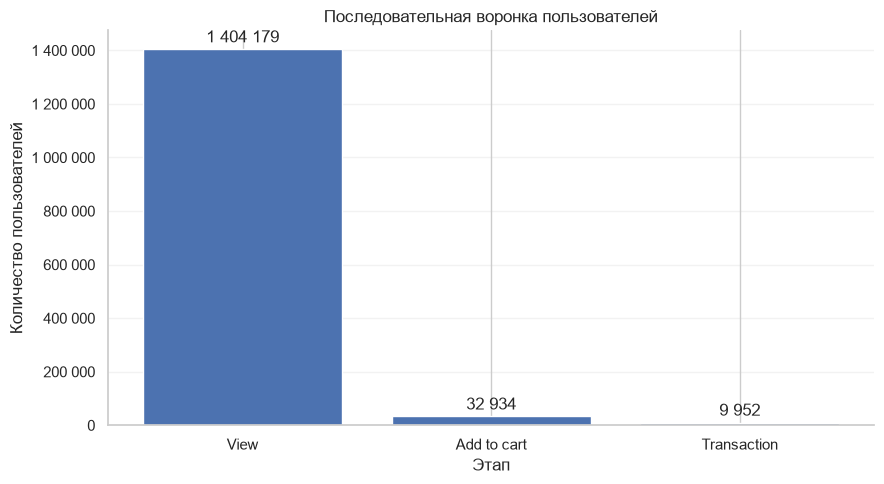

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    funnel_counts.index,
    funnel_counts.values
)

ax.set_title("Последовательная воронка пользователей")
ax.set_xlabel("Этап")
ax.set_ylabel("Количество пользователей")
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
)

for bar, value in zip(bars, funnel_counts.values):
    ax.annotate(
        f"{value:,.0f}".replace(",", " "),
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_user_conversion_funnel.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [71]:
funnel_loss = pd.DataFrame({
    "transition": ["View → Add to cart", "Add to cart → Transaction"],
    "users_before": [view_users, cart_users],
    "users_after": [cart_users, transaction_users],
})

funnel_loss["users_lost"] = (
    funnel_loss["users_before"] - funnel_loss["users_after"]
)

funnel_loss["drop_off_rate"] = (
    funnel_loss["users_lost"] / funnel_loss["users_before"].replace(0, np.nan)
)

display(funnel_loss.style.format({
    "users_before": "{:,.0f}",
    "users_after": "{:,.0f}",
    "users_lost": "{:,.0f}",
    "drop_off_rate": "{:.2%}"
}))

,transition,users_before,users_after,users_lost,drop_off_rate
0,View → Add to cart,"1,404,179","32,934","1,371,245",97.65%
1,Add to cart → Transaction,"32,934","9,952","22,982",69.78%


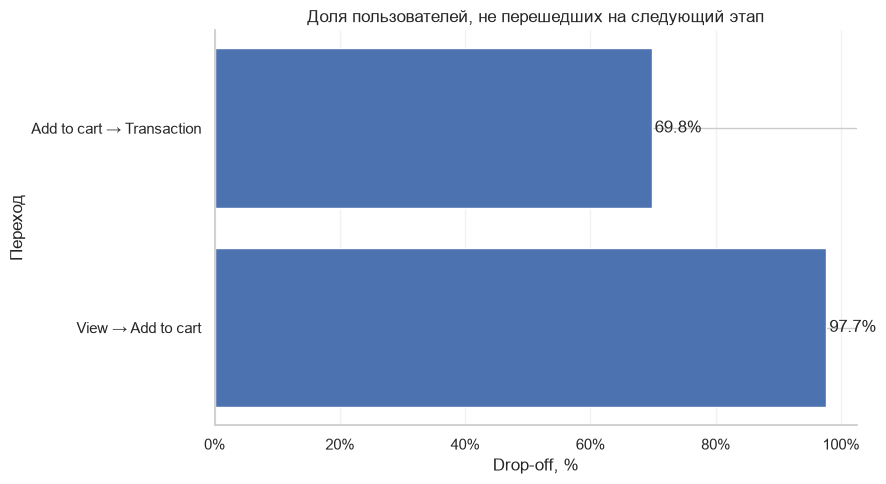

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    funnel_loss["transition"],
    funnel_loss["drop_off_rate"] * 100
)

ax.set_title("Доля пользователей, не перешедших на следующий этап")
ax.set_xlabel("Drop-off, %")
ax.set_ylabel("Переход")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, value in zip(bars, funnel_loss["drop_off_rate"]):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1%}",
        va="center"
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_funnel_dropoff.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [73]:
user_funnel["view_to_cart_hours"] = (
    user_funnel["cart_ts"] - user_funnel["view_ts"]
) / 1000 / 60 / 60

user_funnel["cart_to_transaction_hours"] = (
    user_funnel["transaction_ts"] - user_funnel["cart_ts"]
) / 1000 / 60 / 60

user_funnel["view_to_transaction_hours"] = (
    user_funnel["transaction_ts"] - user_funnel["view_ts"]
) / 1000 / 60 / 60

time_columns = [
    "view_to_cart_hours",
    "cart_to_transaction_hours",
    "view_to_transaction_hours"
]

time_summary = user_funnel[time_columns].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95]
).T

display(time_summary)

,count,mean,std,min,50%,75%,90%,95%,max
view_to_cart_hours,32934.000,75.306,303.257,0.000,0.061,0.591,94.741,475.611,3215.723
cart_to_transaction_hours,9952.000,13.829,105.949,0.006,0.097,0.270,1.762,20.369,2575.930
view_to_transaction_hours,9952.000,101.516,342.671,0.008,0.392,9.890,219.729,675.012,3143.519


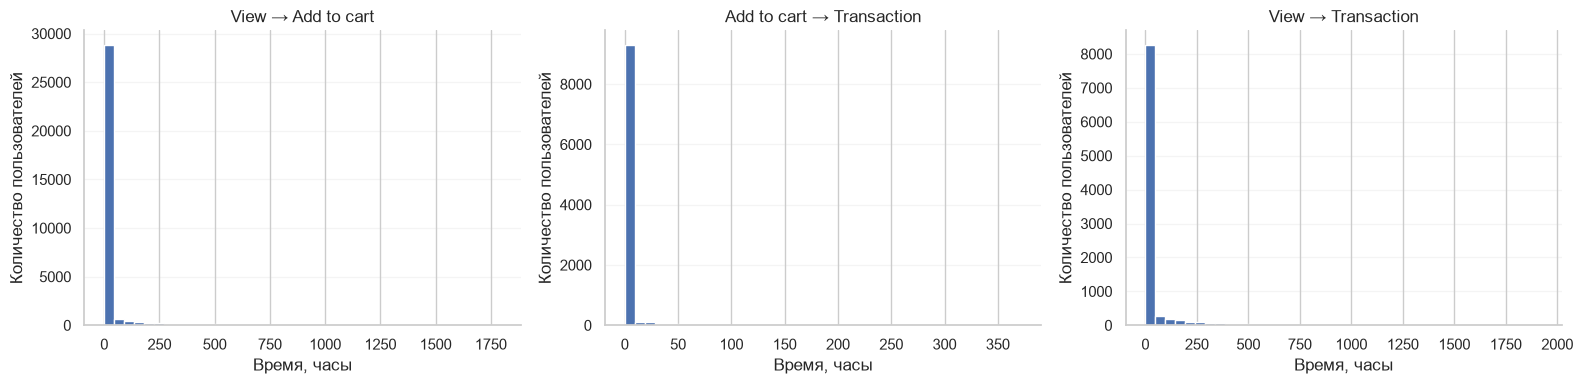

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

plot_titles = [
    "View → Add to cart",
    "Add to cart → Transaction",
    "View → Transaction"
]

for ax, column, title in zip(axes, time_columns, plot_titles):
    values = user_funnel[column].dropna()
    # Ограничиваем визуализацию 99-м перцентилем,
    # но не удаляем наблюдения из исходной таблицы и описательной статистики.
    if len(values):
        upper = values.quantile(0.99)
        ax.hist(values[values <= upper], bins=40)
    ax.set_title(title)
    ax.set_xlabel("Время, часы")
    ax.set_ylabel("Количество пользователей")
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_time_between_funnel_steps.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [75]:
keys = ["visitorid", "itemid"]

pair_views = (
    funnel_events.loc[funnel_events["event"] == "view"]
    .groupby(keys, as_index=False)["timestamp"]
    .min()
    .rename(columns={"timestamp": "view_ts"})
)

pair_cart_candidates = (
    funnel_events.loc[funnel_events["event"] == "addtocart",
                      keys + ["timestamp"]]
    .merge(pair_views, on=keys, how="inner")
)

pair_cart_candidates = pair_cart_candidates[
    pair_cart_candidates["timestamp"] >= pair_cart_candidates["view_ts"]
]

pair_carts = (
    pair_cart_candidates.groupby(keys, as_index=False)["timestamp"]
    .min()
    .rename(columns={"timestamp": "cart_ts"})
)

pair_transaction_candidates = (
    funnel_events.loc[funnel_events["event"] == "transaction",
                      keys + ["timestamp"]]
    .merge(pair_carts, on=keys, how="inner")
)

pair_transaction_candidates = pair_transaction_candidates[
    pair_transaction_candidates["timestamp"] >=
    pair_transaction_candidates["cart_ts"]
]

pair_transactions = (
    pair_transaction_candidates.groupby(keys, as_index=False)["timestamp"]
    .min()
    .rename(columns={"timestamp": "transaction_ts"})
)

item_pair_funnel = (
    pair_views
    .merge(pair_carts, on=keys, how="left")
    .merge(pair_transactions, on=keys, how="left")
)

pair_view_count = len(item_pair_funnel)
pair_cart_count = item_pair_funnel["cart_ts"].notna().sum()
pair_transaction_count = item_pair_funnel["transaction_ts"].notna().sum()

pair_funnel_results = pd.DataFrame({
    "user_item_pairs": [
        pair_view_count,
        pair_cart_count,
        pair_transaction_count
    ],
    "conversion_from_previous": [
        np.nan,
        pair_cart_count / pair_view_count if pair_view_count else np.nan,
        pair_transaction_count / pair_cart_count if pair_cart_count else np.nan
    ],
    "conversion_from_view": [
        1.0 if pair_view_count else np.nan,
        pair_cart_count / pair_view_count if pair_view_count else np.nan,
        pair_transaction_count / pair_view_count if pair_view_count else np.nan
    ]
}, index=["View", "Add to cart", "Transaction"])

display(pair_funnel_results.style.format({
    "user_item_pairs": "{:,.0f}",
    "conversion_from_previous": "{:.2%}",
    "conversion_from_view": "{:.2%}"
}))

,user_item_pairs,conversion_from_previous,conversion_from_view
View,"2,132,127",nan%,100.00%
Add to cart,"45,810",2.15%,2.15%
Transaction,"16,700",36.45%,0.78%


In [76]:
funnel_comparison = pd.DataFrame({
    "user_level": [
        view_users,
        cart_users,
        transaction_users
    ],
    "user_item_level": [
        pair_view_count,
        pair_cart_count,
        pair_transaction_count
    ]
}, index=["View", "Add to cart", "Transaction"])

display(funnel_comparison)

,user_level,user_item_level
View,1404179,2132127
Add to cart,32934,45810
Transaction,9952,16700


In [77]:
all_user_first = (
    funnel_events.pivot_table(
        index="visitorid",
        columns="event",
        values="timestamp",
        aggfunc="min"
    )
)

for event_name in ["view", "addtocart", "transaction"]:
    if event_name not in all_user_first.columns:
        all_user_first[event_name] = np.nan

cart_without_prior_view = (
    all_user_first["addtocart"].notna()
    & (
        all_user_first["view"].isna()
        | (all_user_first["addtocart"] < all_user_first["view"])
    )
)

transaction_without_prior_cart = (
    all_user_first["transaction"].notna()
    & (
        all_user_first["addtocart"].isna()
        | (all_user_first["transaction"] < all_user_first["addtocart"])
    )
)

sequence_diagnostics = pd.Series({
    "Users with cart but no earlier view": int(cart_without_prior_view.sum()),
    "Users with transaction but no earlier cart": int(transaction_without_prior_cart.sum())
}, name="users")

display(sequence_diagnostics.to_frame())

,users
Users with cart but no earlier view,5450
Users with transaction but no earlier cart,1272


In [78]:
OUTPUT_DIR = TABLES_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

funnel_results.to_csv(OUTPUT_DIR / "user_funnel.csv")
funnel_loss.to_csv(OUTPUT_DIR / "funnel_dropoff.csv", index=False)
time_summary.to_csv(OUTPUT_DIR / "funnel_time_summary.csv")
pair_funnel_results.to_csv(OUTPUT_DIR / "user_item_funnel.csv")
sequence_diagnostics.to_csv(OUTPUT_DIR / "funnel_sequence_diagnostics.csv")

print("Результаты сохранены в:", OUTPUT_DIR)

Результаты сохранены в: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics/reports/tables
